<a href="https://colab.research.google.com/github/nilatasoy2004/rfm-customer-segmentation/blob/main/RFM_Customer_Segmentation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Customer Segmentation with RFM Analysis
**Author:** Nil Atasoy

**Question:** Which customers drive an online retailer's revenue, and how should marketing treat each group differently?

**Data:** [UCI Online Retail II](https://archive.ics.uci.edu/dataset/502/online+retail+ii), about 1M transactions from a UK-based online gift retailer, Dec 2009 to Dec 2011.

**Method:** RFM (Recency, Frequency, Monetary) scoring, rule-based segments, and a k-means clustering check.

## 1. Setup

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os, urllib.request, zipfile

pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
plt.rcParams["figure.figsize"] = (10, 5)

## 2. Download and load the data
The file is an Excel workbook with one sheet per year. Reading it takes 1 to 3 minutes.

In [3]:
URL = "https://archive.ics.uci.edu/static/public/502/online+retail+ii.zip"
XLSX = "online_retail_II.xlsx"

if not os.path.exists(XLSX):
    urllib.request.urlretrieve(URL, "online_retail_ii.zip")
    with zipfile.ZipFile("online_retail_ii.zip") as z:
        z.extractall(".")

sheets = pd.read_excel(XLSX, sheet_name=None)   # all sheets
df_raw = pd.concat(sheets.values(), ignore_index=True)
print(df_raw.shape)
df_raw.head()

(1067371, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,"13,085.00",United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,"13,085.00",United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,"13,085.00",United Kingdom


In [4]:
df_raw.info()
df_raw.isna().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[ns]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 65.1+ MB


,0
Invoice,0
StockCode,0
Description,4382
Quantity,0
InvoiceDate,0
Price,0
Customer ID,243007
Country,0


## 3. Clean the data
- Drop rows with no `Customer ID` (we can't segment anonymous buyers).
- Drop cancelled invoices (invoice numbers starting with "C") and rows with zero or negative quantity or price.
- Drop exact duplicate rows.
- Add `Revenue = Quantity × Price`.

In [5]:
df = df_raw.copy()
steps = {"raw rows": len(df)}

df = df.dropna(subset=["Customer ID"]);                     steps["with customer id"] = len(df)
df = df[~df["Invoice"].astype(str).str.startswith("C")];   steps["no cancellations"] = len(df)
df = df[(df["Quantity"] > 0) & (df["Price"] > 0)];         steps["positive qty & price"] = len(df)
df = df.drop_duplicates();                                  steps["no duplicates"] = len(df)

df["Customer ID"] = df["Customer ID"].astype(int)
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
df["Revenue"] = df["Quantity"] * df["Price"]

pd.Series(steps, name="rows")

,rows
raw rows,1067371
with customer id,824364
no cancellations,805620
positive qty & price,805549
no duplicates,779425


In [6]:
print("Customers:", df["Customer ID"].nunique())
print("Invoices: ", df["Invoice"].nunique())
print("Period:   ", df["InvoiceDate"].min().date(), "to", df["InvoiceDate"].max().date())
print(f"Revenue:   £{df['Revenue'].sum():,.0f}")

Customers: 5878
Invoices:  36969
Period:    2009-12-01 to 2011-12-09
Revenue:   £17,374,804


## 4. Build the RFM table
For each customer:
- **Recency:** days since their last purchase (lower is better)
- **Frequency:** number of distinct invoices
- **Monetary:** total revenue

We measure recency from one day after the last date in the data.

In [7]:
snapshot = df["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm = df.groupby("Customer ID").agg(
    Recency=("InvoiceDate", lambda d: (snapshot - d.max()).days),
    Frequency=("Invoice", "nunique"),
    Monetary=("Revenue", "sum"),
)
rfm.describe()

,Recency,Frequency,Monetary
count,"5,878.00","5,878.00","5,878.00"
mean,201.33,6.29,"2,955.90"
std,209.34,13.01,"14,440.85"
min,1.00,1.00,2.95
25%,26.00,1.00,342.28
50%,96.00,3.00,867.74
75%,380.00,7.00,"2,248.30"
max,739.00,398.00,"580,987.04"


## 5. Score customers from 1 to 5
Each metric is split into five equal-sized groups (quintiles). 5 is best: most recent, most frequent, highest spend.

In [8]:
rfm["R"] = pd.qcut(rfm["Recency"].rank(method="first"), 5, labels=[5, 4, 3, 2, 1]).astype(int)
# rank first so that ties (many customers with 1 order) don't break qcut
rfm["F"] = pd.qcut(rfm["Frequency"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["M"] = pd.qcut(rfm["Monetary"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm.head()

,Recency,Frequency,Monetary,R,F,M
Customer ID,,,,,,
12346,326,12,"77,556.46",2,5,5
12347,2,8,"4,921.53",5,4,5
12348,75,5,"2,019.40",3,4,4
12349,19,4,"4,428.69",5,3,5
12350,310,1,334.40,2,1,2


## 6. Assign segments
A common rule set based on the Recency score and the average of Frequency and Monetary scores.

| Segment | Rule | Marketing meaning |
|---|---|---|
| Champions | R ≥ 4, FM ≥ 4 | Recent, frequent, high spend. Reward them. |
| Loyal | R ≥ 3, FM ≥ 3 | Regular buyers. Upsell, loyalty programme. |
| Potential Loyalists | R ≥ 4, FM 2 to 3 | Recent with some history. Nurture. |
| New Customers | R ≥ 4, FM < 2 | Just arrived. Onboard well. |
| At Risk | R ≤ 2, FM ≥ 3 | Used to be valuable, now quiet. Win back. |
| Needs Attention | R = 3, FM < 3 | Average and slipping. |
| Hibernating | R ≤ 2, FM 2 to 3 | Low and inactive. Low-cost reactivation. |
| Lost | R ≤ 2, FM < 2 | Very low value. Minimal spend. |

In [9]:
rfm["FM"] = (rfm["F"] + rfm["M"]) / 2

def segment(row):
    r, fm = row["R"], row["FM"]
    if r >= 4 and fm >= 4: return "Champions"
    if r >= 3 and fm >= 3: return "Loyal"
    if r >= 4 and fm >= 2: return "Potential Loyalists"
    if r >= 4:             return "New Customers"
    if r <= 2 and fm >= 3: return "At Risk"
    if r == 3:             return "Needs Attention"
    if fm >= 2:            return "Hibernating"
    return "Lost"

rfm["Segment"] = rfm.apply(segment, axis=1)
rfm["Segment"].value_counts()

,count
Segment,
Champions,1316
Loyal,1213
Lost,1027
At Risk,684
Hibernating,640
Needs Attention,441
Potential Loyalists,339
New Customers,218


## 7. Segment profile

In [10]:
summary = rfm.groupby("Segment").agg(
    Customers=("Recency", "size"),
    Avg_Recency_days=("Recency", "mean"),
    Avg_Orders=("Frequency", "mean"),
    Avg_Spend=("Monetary", "mean"),
    Revenue=("Monetary", "sum"),
)
summary["Customer_%"] = 100 * summary["Customers"] / summary["Customers"].sum()
summary["Revenue_%"] = 100 * summary["Revenue"] / summary["Revenue"].sum()
summary = summary.sort_values("Revenue", ascending=False)
summary

,Customers,Avg_Recency_days,Avg_Orders,Avg_Spend,Revenue,Customer_%,Revenue_%
Segment,,,,,,,
Champions,1316,19.79,16.90,"9,070.35","11,936,576.35",22.39,68.70
Loyal,1213,73.73,5.80,"2,288.95","2,776,494.78",20.64,15.98
At Risk,684,364.38,5.35,"2,434.00","1,664,858.28",11.64,9.58
Hibernating,640,417.05,1.91,567.00,"362,881.85",10.89,2.09
Lost,1027,475.40,1.08,212.36,"218,089.13",17.47,1.26
Needs Attention,441,109.31,1.62,416.66,"183,745.29",7.50,1.06
Potential Loyalists,339,27.13,2.19,539.46,"182,877.18",5.77,1.05
New Customers,218,28.32,1.13,226.06,"49,281.41",3.71,0.28


## 8. Charts

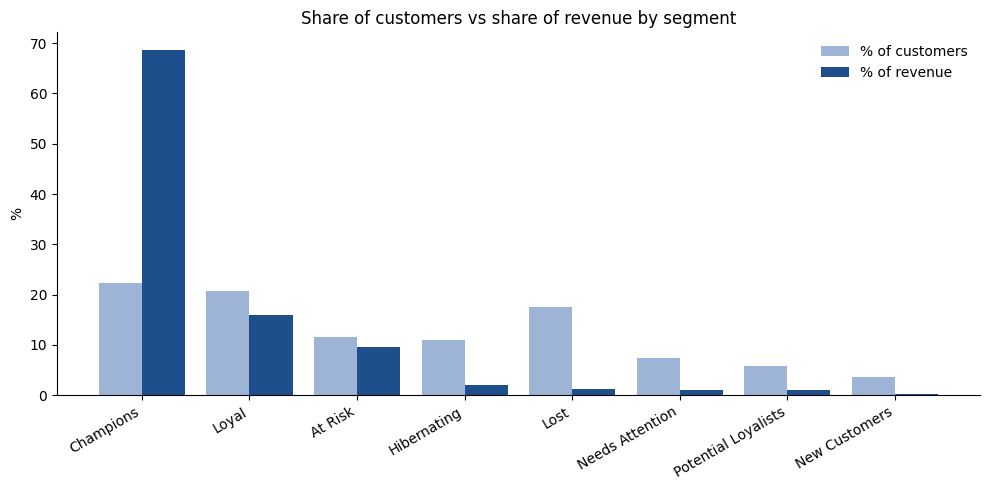

In [11]:
order = summary.index
x = np.arange(len(order))
fig, ax = plt.subplots()
ax.bar(x - 0.2, summary["Customer_%"], width=0.4, label="% of customers", color="#9db4d6")
ax.bar(x + 0.2, summary["Revenue_%"], width=0.4, label="% of revenue", color="#1f4e8c")
ax.set_xticks(x); ax.set_xticklabels(order, rotation=30, ha="right")
ax.set_ylabel("%"); ax.set_title("Share of customers vs share of revenue by segment")
ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig("segments_share.png", dpi=150); plt.show()

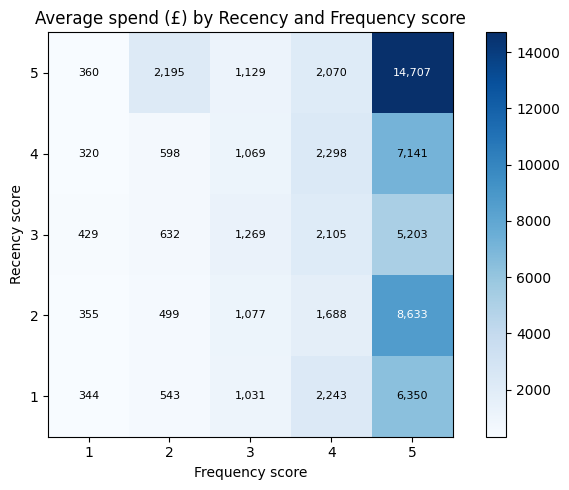

In [12]:
heat = rfm.pivot_table(index="R", columns="F", values="Monetary", aggfunc="mean").sort_index(ascending=False)
fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(heat, cmap="Blues")
ax.set_xticks(range(5)); ax.set_xticklabels(heat.columns)
ax.set_yticks(range(5)); ax.set_yticklabels(heat.index)
ax.set_xlabel("Frequency score"); ax.set_ylabel("Recency score")
ax.set_title("Average spend (£) by Recency and Frequency score")
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        v = heat.iloc[i, j]
        if pd.notna(v):
            ax.text(j, i, f"{v:,.0f}", ha="center", va="center",
                    color="white" if v > np.nanmax(heat.values) / 2 else "black", fontsize=8)
plt.colorbar(im, ax=ax); plt.tight_layout(); plt.savefig("rfm_heatmap.png", dpi=150); plt.show()

## 9. Check: does k-means find similar groups?
RFM rules are set by hand. As a check, we let k-means clustering group customers on log-scaled, standardised R, F and M, and compare its clusters with our segments.

In [16]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

X = StandardScaler().fit_transform(np.log1p(rfm[["Recency", "Frequency", "Monetary"]]))

scores = {}
for k in range(2, 9):
    labels = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(X)
    scores[k] = silhouette_score(X, labels, sample_size=min(5000, len(X)), random_state=42)
pd.Series(scores, name="silhouette")

,silhouette
2,0.44
3,0.35
4,0.37
5,0.34
6,0.34
7,0.31
8,0.30


In [14]:
K = 4   # change this to the k you choose from the scores above (higher silhouette = better separated)
rfm["Cluster"] = KMeans(n_clusters=K, n_init=10, random_state=42).fit_predict(X)

print(rfm.groupby("Cluster")[["Recency", "Frequency", "Monetary"]].median())
pd.crosstab(rfm["Segment"], rfm["Cluster"])

         Recency  Frequency  Monetary
Cluster                              
0         402.00       1.00    273.31
1          24.00       3.00    734.12
2          17.00      13.00  4,986.11
3         186.00       4.00  1,450.04


Cluster,0,1,2,3
Segment,,,,
At Risk,20,0,14,650
Champions,0,151,1068,97
Hibernating,571,0,0,69
Lost,1027,0,0,0
Loyal,4,485,114,610
Needs Attention,310,98,0,33
New Customers,39,179,0,0
Potential Loyalists,2,337,0,0


## 10. Key numbers for the write-up
Run this cell and use its output for the summary below. Don't type numbers by hand.

In [15]:
top20 = rfm["Monetary"].sort_values(ascending=False)
top20_share = 100 * top20.head(int(len(top20) * 0.2)).sum() / top20.sum()
s = summary

print(f"Customers analysed: {len(rfm):,}  |  Transactions after cleaning: {len(df):,}")
print(f"Top 20% of customers by spend generate {top20_share:.1f}% of revenue")
for seg in ["Champions", "Loyal", "At Risk"]:
    if seg in s.index:
        print(f"{seg}: {s.loc[seg,'Customer_%']:.1f}% of customers, {s.loc[seg,'Revenue_%']:.1f}% of revenue, "
              f"avg spend £{s.loc[seg,'Avg_Spend']:,.0f}")
if "At Risk" in s.index:
    print(f"Revenue from At Risk customers: £{s.loc['At Risk','Revenue']:,.0f}")

Customers analysed: 5,878  |  Transactions after cleaning: 779,425
Top 20% of customers by spend generate 77.2% of revenue
Champions: 22.4% of customers, 68.7% of revenue, avg spend £9,070
Loyal: 20.6% of customers, 16.0% of revenue, avg spend £2,289
At Risk: 11.6% of customers, 9.6% of revenue, avg spend £2,434
Revenue from At Risk customers: £1,664,858


## 11. Findings and recommendations


1. **Revenue is highly concentrated:** The top 20% of customers by spend generate 77.2% of revenue, a stronger concentration than the classic 80/20 rule suggests for most of the base.
2. **Champions carry the business:** Champions are 22.4% of customers but 68.7% of revenue, with an average spend of £9,070, about four times that of Loyal customers (£2,289). Losing even a few of them would hurt revenue far more than losing many low-value customers, so retention spend should focus here (account management, early access, loyalty rewards).
3. **At Risk customers are a clear win-back target:** At Risk customers (11.6% of the base) used to buy often and spent £2,434 on average, more than Loyal customers, but have not bought recently. Together they account for £1.66M of past revenue, which makes a targeted win-back campaign worth testing.
4. **Recommendation:** Set the marketing budget by segment value rather than spreading it evenly: protect Champions, grow Loyal customers into Champions, run win-back campaigns for At Risk customers, and keep spending on Lost and Hibernating customers low.


**Limitations:** the data covers 2009 to 2011, one UK retailer with many wholesale buyers, and has no data on margins or marketing costs. The segments describe past behaviour and do not predict it. The RFM method itself is still widely used.